# DecFM 2D Mixture: Design and Properties

Reference notebook for the two-dimensional confounded design used in the counterfactual sampling
experiments. It documents the generating mechanism, the confounding channel, the resulting shift
between observed and interventional outcome laws, and the overlap conditions that govern estimation
difficulty. No estimator is fitted here.

In [1]:
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.append("../../src")

from causality_utils import effective_sample_size
from data_utils import sample_decfm_2d_data
from metric_utils import sliced_wasserstein

np.random.seed(0)


## 1. Design

Dance et al. (2026), Appendix B.2.2:

$$
X \sim \mathcal N(0, I_2), \qquad
A \mid x \sim \mathrm{Bernoulli}\big(e(x)\big), \quad e(x) = \sigma(\gamma\, w^\top x), \quad w = (1,-1)/\sqrt 2,
$$

$$
Y = X + \varepsilon, \qquad
\varepsilon \sim \tfrac12\, \mathcal N(0, \sigma^2 I_2) + \tfrac12\, \mathcal N\big((\delta,\delta), \sigma^2 I_2\big),
$$

with $\gamma = 3$, $\delta = 2$, $\sigma = 0.2$.

Two structural consequences define the estimation problem:

- $Y \perp A \mid X$, so $P_{Y(0)} = P_{Y(1)} = P_Y$: both interventional laws equal the outcome marginal.
- $A \not\perp X$, so $P_{Y \mid A=a} \neq P_Y$: conditioning on a treatment arm tilts the context
  distribution along $w$, and with it the outcome distribution.

The target is therefore known in closed form as the marginal $P_Y$, and any discrepancy between a
sampler's output and $P_Y$ measures residual confounding.

In [2]:
n = 1000
data = sample_decfm_2d_data(n_samples=n, confounding_strength=3.0, mixture_delta=2.0, seed=601)

X = data["X"].numpy()
A = data["A_logged"].numpy().ravel()
Y = data["Y_logged"].numpy()
Y_oracle = data["Y_oracle"].numpy()
propensity = data["propensity"].numpy()
weights = {0: data["importance_weights_a0"].numpy(), 1: data["importance_weights_a1"].numpy()}

w_confounding = np.array([1.0, -1.0]) / np.sqrt(2.0)
print(f"n = {n},   P(A = 1) = {A.mean():.3f},   arm sizes = {int((A == 0).sum())} / {int((A == 1).sum())}")

n = 1000,   P(A = 1) = 0.487,   arm sizes = 513 / 487


## 2. Confounding Channel

The treatment depends on the context only through the scalar projection $w^\top x$, which is the
single direction along which the observed arms are tilted.

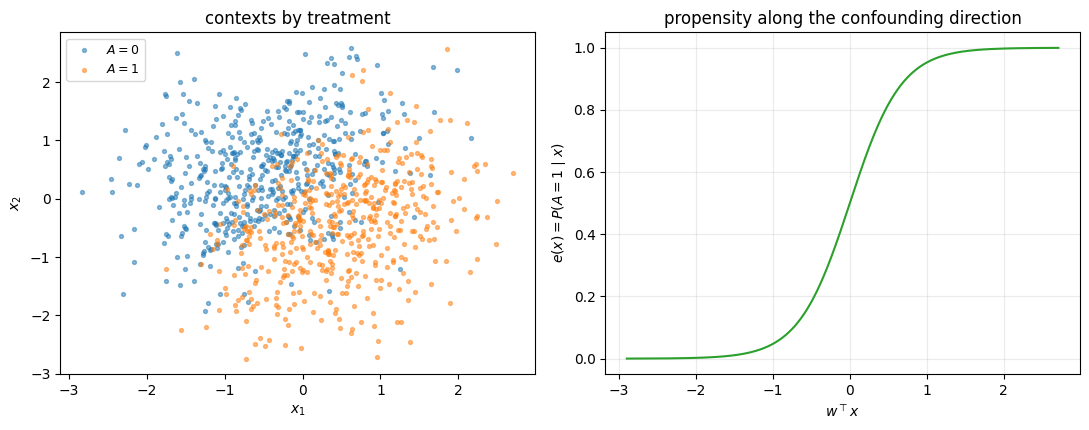

In [3]:
projection = X @ w_confounding
order = np.argsort(projection)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for a, colour in ((0, "tab:blue"), (1, "tab:orange")):
    axes[0].scatter(*X[A == a].T, s=8, alpha=0.5, color=colour, label=f"$A = {a}$")
axes[0].set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
axes[0].set_title("contexts by treatment")
axes[0].legend(fontsize=9)

axes[1].plot(projection[order], propensity[order], color="tab:green")
axes[1].set_xlabel(r"$w^\top x$")
axes[1].set_ylabel(r"$e(x) = P(A = 1 \mid x)$")
axes[1].set_title(r"propensity along the confounding direction")
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 3. Outcome Law

The interventional law $P_Y$ is the bimodal mixture. Each observed arm is a tilted version of it:
arm $1$ over-represents large $w^\top x$ and arm $0$ under-represents it. The rightmost panel
projects all three laws onto $w$, where the shift is a shift in location.

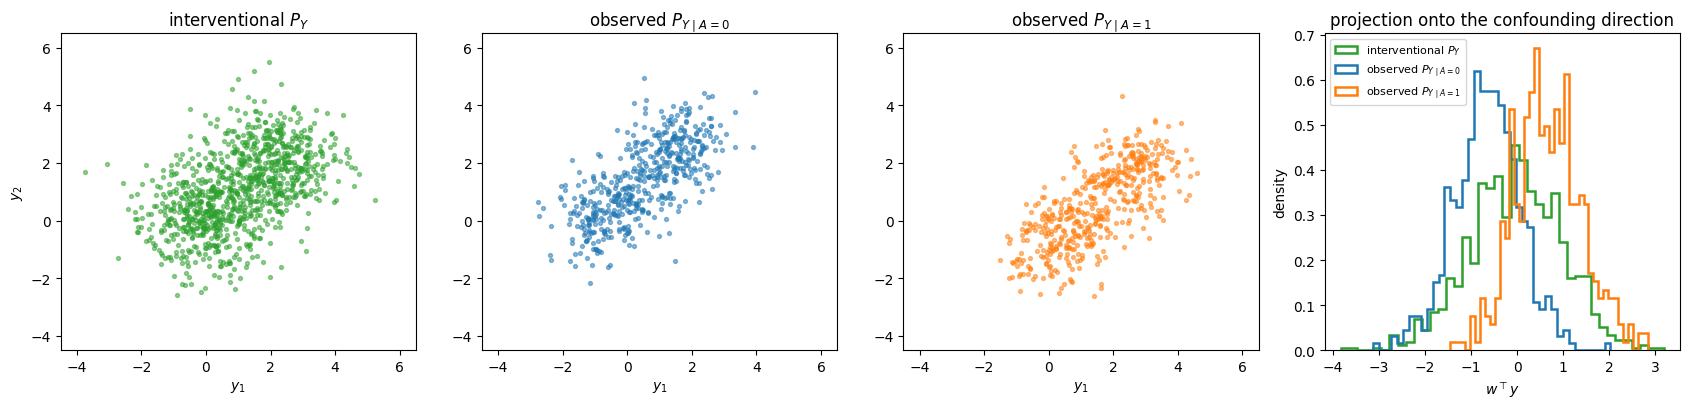

sample                 SW1 to P_Y
observed arm 0              0.421
observed arm 1              0.464


In [4]:
clouds = [(r"interventional $P_Y$", Y_oracle, "tab:green"),
          (r"observed $P_{Y \mid A=0}$", Y[A == 0], "tab:blue"),
          (r"observed $P_{Y \mid A=1}$", Y[A == 1], "tab:orange")]

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, (title, cloud, colour) in zip(axes, clouds):
    ax.scatter(*cloud.T, s=8, alpha=0.5, color=colour)
    ax.set_title(title)
    ax.set_xlabel("$y_1$")
    ax.set_xlim(-4.5, 6.5)
    ax.set_ylim(-4.5, 6.5)
axes[0].set_ylabel("$y_2$")

for title, cloud, colour in clouds:
    axes[3].hist(cloud @ w_confounding, bins=40, density=True, histtype="step",
                 lw=1.8, color=colour, label=title)
axes[3].set_xlabel(r"$w^\top y$")
axes[3].set_ylabel("density")
axes[3].set_title("projection onto the confounding direction")
axes[3].legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"{'sample':20s} {'SW1 to P_Y':>12s}")
for a in (0, 1):
    print(f"{'observed arm ' + str(a):20s} {sliced_wasserstein(Y[A == a], Y_oracle, p=1, seed=0).item():12.3f}")

## 4. Overlap

Deterministic-intervention importance weights are $w_i^{(a)} = \mathbf 1\{a_i = a\} / e_a(x_i)$ with
$e_1 = e$ and $e_0 = 1 - e$. Because $\gamma = 3$ pushes $e(x)$ close to $0$ and $1$ in the tails of
$w^\top x$, a logged observation that lands in the opposite arm's tail receives a very large weight.
The effective sample size quantifies how much of each arm is actually usable.

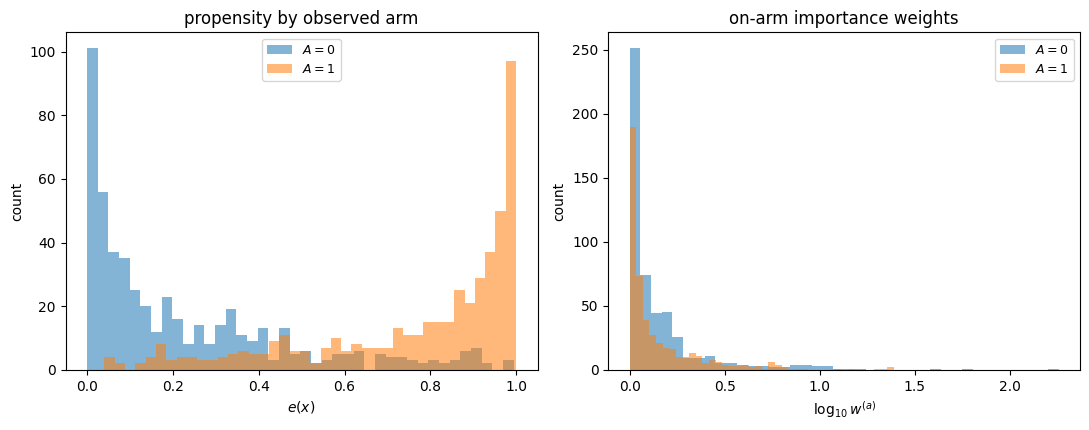

 arm   size      ESS   ESS / size   max weight
   0    513     32.5        0.063        180.7
   1    487    185.0        0.380         24.6


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for a, colour in ((0, "tab:blue"), (1, "tab:orange")):
    axes[0].hist(propensity[A == a], bins=40, alpha=0.55, color=colour, label=f"$A = {a}$")
    axes[1].hist(np.log10(weights[a][A == a]), bins=40, alpha=0.55, color=colour, label=f"$A = {a}$")
axes[0].set_xlabel("$e(x)$")
axes[0].set_ylabel("count")
axes[0].set_title("propensity by observed arm")
axes[0].legend(fontsize=9)
axes[1].set_xlabel(r"$\log_{10} w^{(a)}$")
axes[1].set_ylabel("count")
axes[1].set_title("on-arm importance weights")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"{'arm':>4s} {'size':>6s} {'ESS':>8s} {'ESS / size':>12s} {'max weight':>12s}")
for a in (0, 1):
    on_arm = weights[a][A == a]
    ess = effective_sample_size(on_arm)
    print(f"{a:>4d} {len(on_arm):6d} {ess:8.1f} {ess / len(on_arm):12.3f} {on_arm.max():12.1f}")

## 5. Role of the Confounding Strength

$\gamma$ controls both axes of difficulty simultaneously: the distance the sampler must transport
(left) and the overlap available to estimate the target (right). Values are averaged over five
seeds, with error bars giving the standard deviation across seeds.

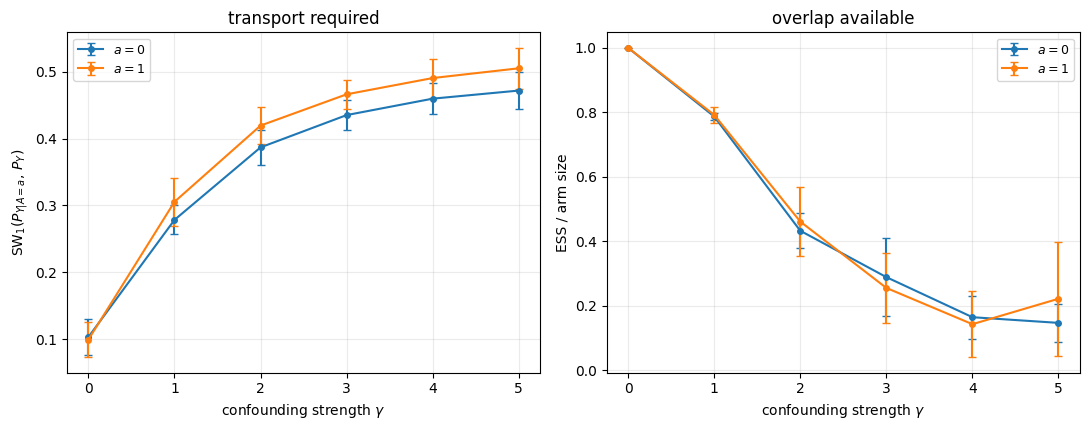

In [6]:
gammas = [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
seeds = range(5)
shift = {0: [], 1: []}
ess_fraction = {0: [], 1: []}

for gamma in gammas:
    per_seed = {0: ([], []), 1: ([], [])}
    for seed in seeds:
        d = sample_decfm_2d_data(n_samples=n, confounding_strength=gamma,
                                 mixture_delta=2.0, seed=seed)
        A_s = d["A_logged"].numpy().ravel()
        Y_s = d["Y_logged"].numpy()
        for a in (0, 1):
            on_arm = d[f"importance_weights_a{a}"].numpy()[A_s == a]
            per_seed[a][0].append(sliced_wasserstein(Y_s[A_s == a], d["Y_oracle"].numpy(), p=1, seed=0).item())
            per_seed[a][1].append(effective_sample_size(on_arm) / len(on_arm))
    for a in (0, 1):
        shift[a].append(per_seed[a][0])
        ess_fraction[a].append(per_seed[a][1])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for a, colour in ((0, "tab:blue"), (1, "tab:orange")):
    for ax, values, label in ((axes[0], shift[a], r"SW$_1(P_{Y|A=a},\, P_Y)$"),
                              (axes[1], ess_fraction[a], "ESS / arm size")):
        values = np.array(values)
        ax.errorbar(gammas, values.mean(axis=1), yerr=values.std(axis=1),
                    marker="o", ms=4, capsize=3, color=colour, label=f"$a = {a}$")
        ax.set_xlabel(r"confounding strength $\gamma$")
        ax.set_ylabel(label)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=9)
axes[0].set_title("transport required")
axes[1].set_title("overlap available")
fig.tight_layout()
plt.show()

## Summary

- The interventional target is the outcome marginal $P_Y$, known by construction, so sampler quality
  is measured directly against a fresh draw of $P_Y$.
- Confounding acts through a single direction $w$; both observed arms are location shifts of $P_Y$
  along $w$, of opposite sign and comparable size.
- Overlap degrades sharply with $\gamma$ and is the binding constraint at $\gamma = 3$: the on-arm
  effective sample size is a small fraction of the arm size, and individual weights reach two orders
  of magnitude. Estimation error, not sampler error, dominates in this regime.
- Overlap is also highly variable across seeds at fixed $\gamma$, so single-seed results should not
  be read as characteristic of the design.